# Session 02: The Hidden Shape

**Companion notebook to the Session 02 lecture notes.**

In Session 0, physics told us the shape. In Session 1, physics told us the coordinates. This session asks: **what if physics does not tell us?** Can we discover useful coordinates from the data alone?

The notebook has six sections:

1. **Recreate the cantilever**, and ask PCA to find its coordinates.
2. **Variance sweep** — under what conditions does PCA recover the physical axes?
3. **Failure mode** — uncorrelated is not the same as independent.
4. **Visualization caution** — t-SNE is a picture, not a representation.
5. **Industrial example** — sensor fusion on a synthetic wind turbine.

Run every cell in order. The plots are the lesson.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
np.random.seed(0)

plt.rcParams['figure.figsize'] = (7, 6)
plt.rcParams['figure.dpi'] = 100

COLOR_A = '#1B7F79'    # teal — positive bending / class 1
COLOR_B = '#C2571A'    # amber — other class
COLOR_LINE = '#1B2A4A' # navy — ideal / reference
COLOR_PC1 = '#0E7C7B'
COLOR_PC2 = '#D97706'
COLOR_PHYS = '#5B2C6F'

---

# Section 1 — The cantilever, without physics

Recall Session 1. Two strain gauges at the same cross-section measure

$$\varepsilon_{\mathrm{top}} = \varepsilon_a + \varepsilon_b + \eta_1, \qquad \varepsilon_{\mathrm{bottom}} = \varepsilon_a - \varepsilon_b + \eta_2.$$

Physics gave us the change of basis. In Session 1 we used it. **Now let us pretend we never had it.**

We only see the raw readings $(\varepsilon_{\mathrm{top}}, \varepsilon_{\mathrm{bottom}})$. Can PCA find a better coordinate system for us?

In [2]:
rng = np.random.default_rng(0)
n = 500

# Two independent physical causes, comparable variance
axial   = rng.normal(0, 1.0, n)
bending = rng.normal(0, 1.0, n)

# Small measurement noise
noise = 0.05 * rng.normal(0, 1, (n, 2))

# Raw sensor readings
top    = axial + bending + noise[:, 0]
bottom = axial - bending + noise[:, 1]
X_raw  = np.c_[top, bottom]

# Class label for later
y = (bending > 0).astype(int)

print(f"Samples: {n}")
print(f"Top strain    — std: {top.std():.3f}")
print(f"Bottom strain — std: {bottom.std():.3f}")
print(f"Axial (hidden) — std: {axial.std():.3f}")
print(f"Bending (hidden) — std: {bending.std():.3f}")

Samples: 500
Top strain    — std: 1.386
Bottom strain — std: 1.377
Axial (hidden) — std: 1.014
Bending (hidden) — std: 0.938


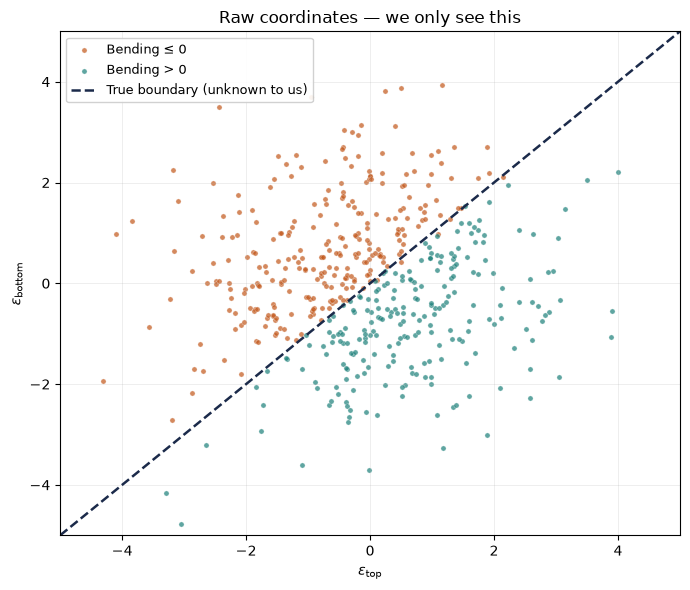

In [3]:
fig, ax = plt.subplots()

for cls, color, label in [(0, COLOR_B, 'Bending ≤ 0'),
                          (1, COLOR_A, 'Bending > 0')]:
    mask = (y == cls)
    ax.scatter(top[mask], bottom[mask], c=color, s=14, alpha=0.7,
               edgecolors='white', linewidths=0.3, label=label)

lim = 5
ax.plot([-lim, lim], [-lim, lim], '--', color=COLOR_LINE,
        linewidth=1.8, label='True boundary (unknown to us)')

ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel(r'$\varepsilon_{\mathrm{top}}$')
ax.set_ylabel(r'$\varepsilon_{\mathrm{bottom}}$')
ax.set_title('Raw coordinates — we only see this')
ax.legend(loc='upper left', framealpha=0.9, fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The true boundary is the diagonal $\varepsilon_{\mathrm{top}} = \varepsilon_{\mathrm{bottom}}$, but we have hidden it. All we have is the point cloud. Time to let PCA choose directions.

In [4]:
from sklearn.decomposition import PCA

# Center (no scaling — both channels have the same units)
X_centered = X_raw - X_raw.mean(axis=0)

pca = PCA(n_components=2).fit(X_centered)

print("Principal directions (rows of components_):")
print(pca.components_)
print()
print("Explained variance ratio:", pca.explained_variance_ratio_)
print()
print("Angle of PC1 from top-strain axis (degrees):",
      np.degrees(np.arctan2(pca.components_[0, 1], pca.components_[0, 0])).round(2))
print("Angle of physical axial axis from top-strain axis (degrees):",
      np.degrees(np.arctan2(1, 1)).round(2))

Principal directions (rows of components_):
[[ 0.73386153  0.67929909]
 [-0.67929909  0.73386153]]

Explained variance ratio: [0.53952514 0.46047486]

Angle of PC1 from top-strain axis (degrees): 42.79
Angle of physical axial axis from top-strain axis (degrees): 45.0


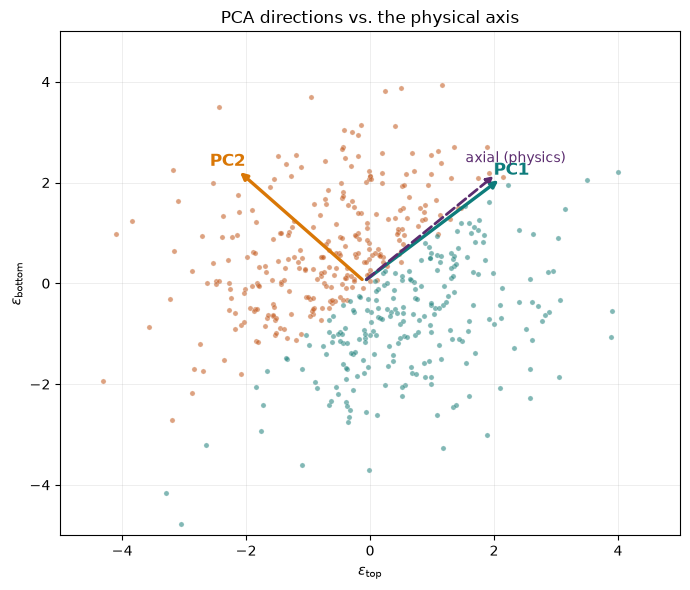

In [5]:
fig, ax = plt.subplots()

for cls, color in [(0, COLOR_B), (1, COLOR_A)]:
    mask = (y == cls)
    ax.scatter(top[mask], bottom[mask], c=color, s=14, alpha=0.55,
               edgecolors='white', linewidths=0.3)

# Draw PCA directions
mean = X_raw.mean(axis=0)
scale = 3.0
for i, (comp, color, name) in enumerate(zip(
        pca.components_, [COLOR_PC1, COLOR_PC2], ['PC1', 'PC2'])):
    ax.annotate('', xy=mean + scale * comp, xytext=mean,
                arrowprops=dict(arrowstyle='-|>', color=color, linewidth=2.4))
    ax.text(*(mean + scale * 1.08 * comp), name, color=color,
            fontsize=12, fontweight='bold', ha='center', va='center')

# Physical axes for comparison
ax.annotate('', xy=mean + scale * np.array([1, 1]) / np.sqrt(2), xytext=mean,
            arrowprops=dict(arrowstyle='-|>', color=COLOR_PHYS,
                            linewidth=2.0, linestyle='--'))
ax.text(*(mean + scale * 1.15 * np.array([1, 1]) / np.sqrt(2)),
        'axial (physics)', color=COLOR_PHYS, fontsize=10,
        ha='center', va='center')

ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel(r'$\varepsilon_{\mathrm{top}}$')
ax.set_ylabel(r'$\varepsilon_{\mathrm{bottom}}$')
ax.set_title('PCA directions vs. the physical axis')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

PCA picked a direction. But is it the *physical* axial axis?

When variances are comparable, PCA rotates arbitrarily within the plane. The components are uncorrelated — but uncorrelated is **not** what physics cares about. Let us be quantitative.

In [6]:
def angle_between(v1, v2):
    v1 = v1 / np.linalg.norm(v1)
    v2 = v2 / np.linalg.norm(v2)
    return np.degrees(np.arccos(np.clip(abs(np.dot(v1, v2)), -1, 1)))

physical_axial = np.array([1, 1]) / np.sqrt(2)
err = angle_between(pca.components_[0], physical_axial)
print(f"Angle between PC1 and the physical axial axis: {err:.1f}°")
print()
print("An angle of 0° means PCA recovered physics. An angle of 45° means")
print("it picked a random direction in the plane.")

Angle between PC1 and the physical axial axis: 2.2°

An angle of 0° means PCA recovered physics. An angle of 45° means
it picked a random direction in the plane.


---

# Section 2 — When does PCA recover physics?

The answer depends on the **variance ratio** of the two hidden causes. If one cause dominates, PCA finds it. If they are comparable, PCA cannot tell them apart.

We will sweep the bending variance over three orders of magnitude and record the angle between PC1 and the physical axial axis.

In [7]:
def make_cantilever(n, sigma_a, sigma_b, seed=0):
    rng = np.random.default_rng(seed)
    a = rng.normal(0, sigma_a, n)
    b = rng.normal(0, sigma_b, n)
    nz = 0.05 * rng.normal(0, 1, (n, 2))
    return np.c_[a + b + nz[:, 0], a - b + nz[:, 1]]

ratios   = np.logspace(-3, 3, 40)   # sigma_b^2 / sigma_a^2
angles   = []

for r in ratios:
    X = make_cantilever(n=2000, sigma_a=1.0, sigma_b=np.sqrt(r))
    Xc = X - X.mean(axis=0)
    p = PCA(n_components=2).fit(Xc)
    angles.append(angle_between(p.components_[0], physical_axial))

angles = np.array(angles)
print(f"At variance ratio 1e-3 (axial dominates): angle = {angles[0]:.1f}°")
print(f"At variance ratio 1e+0 (comparable):       angle = {angles[len(angles)//2-1]:.1f}°")
print(f"At variance ratio 1e+3 (bending dominates): angle = {angles[-1]:.1f}°")

At variance ratio 1e-3 (axial dominates): angle = 0.0°
At variance ratio 1e+0 (comparable):       angle = 5.2°
At variance ratio 1e+3 (bending dominates): angle = 90.0°


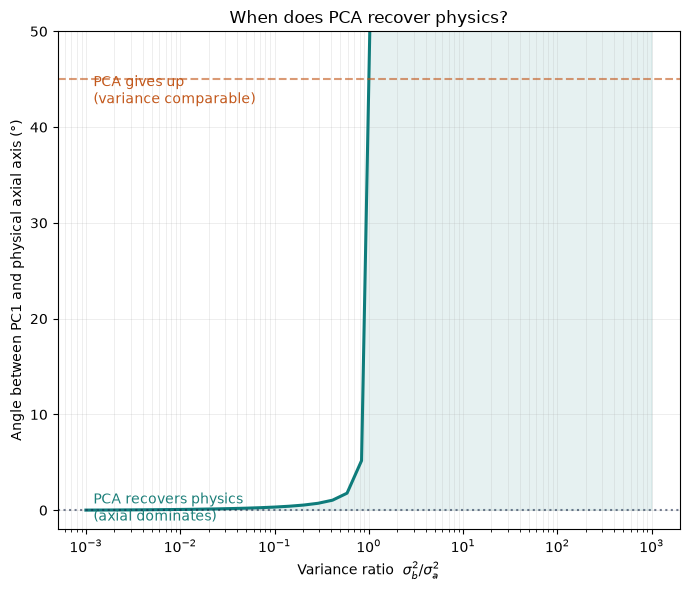

In [8]:
fig, ax = plt.subplots()

ax.semilogx(ratios, angles, color=COLOR_PC1, linewidth=2.2)
ax.axhline(0,  color=COLOR_LINE, linestyle=':', alpha=0.6)
ax.axhline(45, color=COLOR_B, linestyle='--', alpha=0.6)
ax.fill_between(ratios, 0, angles, color=COLOR_PC1, alpha=0.10)

ax.text(1.2e-3, 2, 'PCA recovers physics\n(axial dominates)',
        color=COLOR_A, fontsize=10, va='top')
ax.text(1.2e-3, 42, 'PCA gives up\n(variance comparable)',
        color=COLOR_B, fontsize=10, va='bottom')

ax.set_xlabel(r'Variance ratio  $\sigma_b^2 / \sigma_a^2$')
ax.set_ylabel('Angle between PC1 and physical axial axis (°)')
ax.set_title('When does PCA recover physics?')
ax.set_ylim(-2, 50)
ax.grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()

Read the curve. PCA aligns with the physical axial axis only when that axis carries most of the variance. Once the two causes have comparable variance, the angle collapses to 45° — **PCA has no preference**.

This is the first serious limitation. Variance is not the same as meaning. If the thing we care about (bending) is *not* the thing with the most variance, PCA will bury it.

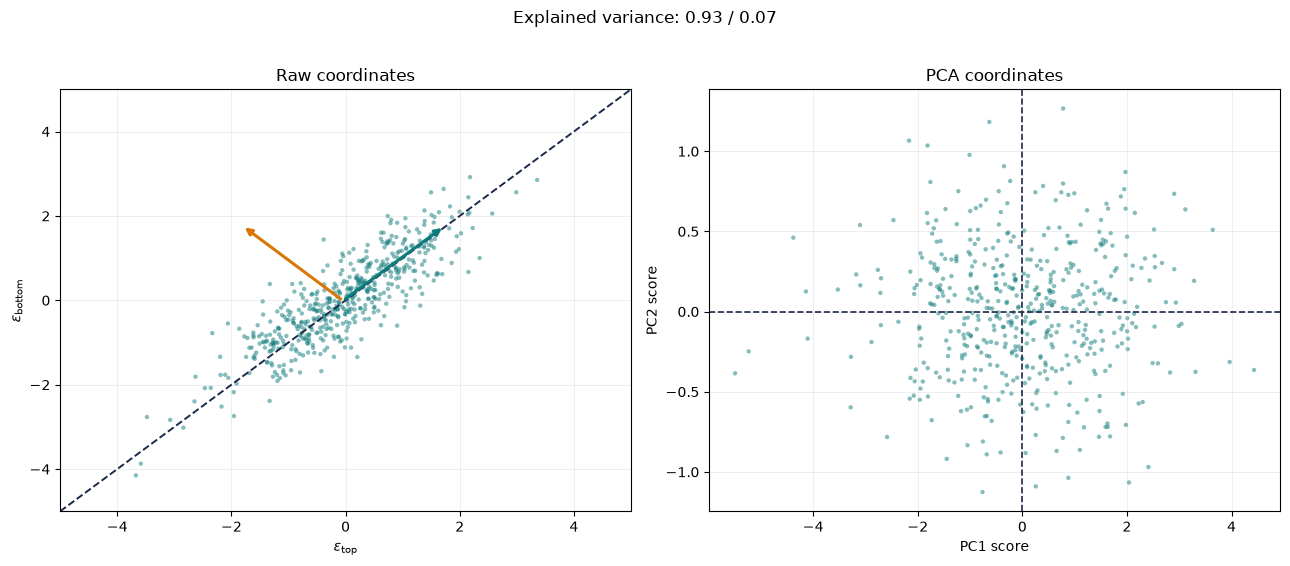


Angle between PC1 and physical axial: 0.2°
If physics dominated, this would be near 0°.


In [9]:
# A concrete case: bending variance is 10x smaller than axial
X = make_cantilever(n=500, sigma_a=1.0, sigma_b=0.3)
Xc = X - X.mean(axis=0)
p = PCA(n_components=2).fit(Xc)

# Project onto PC1 and PC2
Z = p.transform(Xc)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Left: raw coordinates with PCA directions
ax = axes[0]
ax.scatter(X[:, 0], X[:, 1], c=COLOR_PC1, s=10, alpha=0.5,
           edgecolors='none')
m = X.mean(axis=0)
for comp, color, name in zip(p.components_,
                             [COLOR_PC1, COLOR_PC2], ['PC1', 'PC2']):
    ax.annotate('', xy=m + 2.5 * comp, xytext=m,
                arrowprops=dict(arrowstyle='-|>', color=color, linewidth=2.2))
ax.plot([-lim, lim], [-lim, lim], '--', color=COLOR_LINE, linewidth=1.4)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel(r'$\varepsilon_{\mathrm{top}}$')
ax.set_ylabel(r'$\varepsilon_{\mathrm{bottom}}$')
ax.set_title('Raw coordinates')
ax.grid(alpha=0.3)

# Right: PC1 vs PC2
ax = axes[1]
ax.scatter(Z[:, 0], Z[:, 1], c=COLOR_PC1, s=10, alpha=0.5,
           edgecolors='none')
ax.axhline(0, color=COLOR_LINE, linestyle='--', linewidth=1.2)
ax.axvline(0, color=COLOR_LINE, linestyle='--', linewidth=1.2)
ax.set_xlabel('PC1 score')
ax.set_ylabel('PC2 score')
ax.set_title('PCA coordinates')
ax.grid(alpha=0.3)

plt.suptitle(f'Explained variance: {p.explained_variance_ratio_[0]:.2f} / '
             f'{p.explained_variance_ratio_[1]:.2f}', y=1.02)
plt.tight_layout()
plt.show()

# What happens to the physical boundary?
physical_axial = np.array([1, 1]) / np.sqrt(2)
print()
print(f"Angle between PC1 and physical axial: "
      f"{angle_between(p.components_[0], physical_axial):.1f}°")
print(f"If physics dominated, this would be near 0°.")

PCA has found something useful — the direction of maximum spread. But that direction is not the one that separates bending from non-bending. **PCA is a variance engine. It is not a physics engine.**

---

# Section 3 — Uncorrelated is not independent

PCA finds directions that are *linearly uncorrelated*. But two variables can be perfectly dependent and still uncorrelated. The classic example is a circle:

$$x = \cos\theta, \qquad y = \sin\theta, \qquad \theta \sim \mathrm{Uniform}(0, 2\pi).$$

Here $\mathrm{Cov}(x, y) = 0$, but $x^2 + y^2 = 1$ — the two variables are perfectly dependent. PCA will see no structure and give two equally important components.

In [10]:
rng = np.random.default_rng(1)
theta = rng.uniform(0, 2 * np.pi, 600)
X_circle = np.c_[np.cos(theta), np.sin(theta)]

p_circle = PCA(n_components=2).fit(X_circle - X_circle.mean(axis=0))

print("Covariance matrix of the circle data:")
print(np.round(np.cov(X_circle.T), 4))
print()
print("PCA explained variance ratio:",
      np.round(p_circle.explained_variance_ratio_, 4))
print()
print("PCA sees a two-dimensional cloud, because it only measures")
print("linear correlation. The circle has zero linear correlation.")

Covariance matrix of the circle data:
[[ 0.4917 -0.0105]
 [-0.0105  0.5088]]

PCA explained variance ratio: [0.5135 0.4865]

PCA sees a two-dimensional cloud, because it only measures
linear correlation. The circle has zero linear correlation.


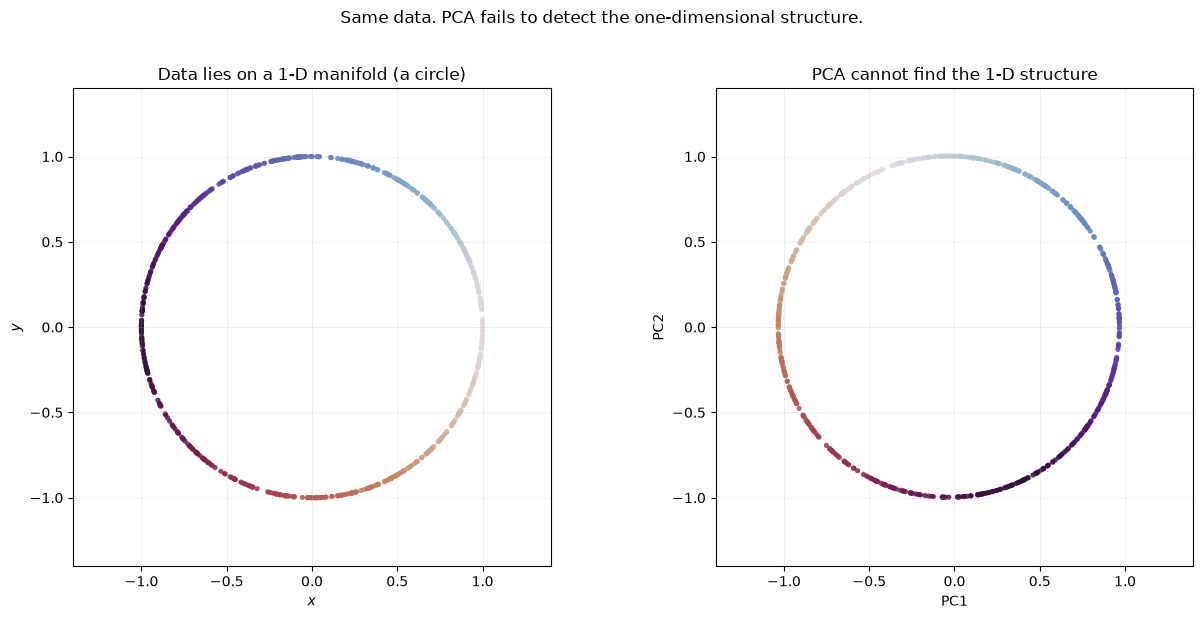

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Left: original circle
ax = axes[0]
ax.scatter(X_circle[:, 0], X_circle[:, 1], c=theta, cmap='twilight',
           s=14, alpha=0.85, edgecolors='none')
ax.set_aspect('equal')
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
ax.set_xlabel('$x$'); ax.set_ylabel('$y$')
ax.set_title('Data lies on a 1-D manifold (a circle)')
ax.grid(alpha=0.3)

# # Right: PCA projection
ax = axes[1]
Z = p_circle.transform(X_circle - X_circle.mean(axis=0))
ax.scatter(Z[:, 0], Z[:, 1], c=theta, cmap='twilight',
           s=14, alpha=0.85, edgecolors='none')
ax.set_aspect('equal')
ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('PCA cannot find the 1-D structure')
ax.grid(alpha=0.3)

plt.suptitle('Same data. PCA fails to detect the one-dimensional structure.',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

This is why **Independent Component Analysis** (ICA) exists. ICA looks for directions along which the data is *statistically independent*, not merely uncorrelated. When the true sources are non-Gaussian and independent, ICA can recover them where PCA cannot.

We will not derive ICA here. The point is to know that PCA is one specific shape assumption: **linear, Gaussian, variance-maximizing**. It is powerful within that assumption and blind outside it.

PCA finds orthogonal directions of maximum variance. ICA finds directions along which the projections are statistically independent. On the *same mixture*, they give different answers. **The right one depends on the shape assumption we are willing to make.**

---

# Section 5 — Visualization: seeing structure, not trusting it

High-dimensional data is often visualized with **t-SNE** or **UMAP**. These are nonlinear dimensionality reduction methods that preserve *local* neighbourhoods. They are useful for looking at data. They are dangerous when used as feature representations.

We will show a cautionary example: the same data under different t-SNE settings.

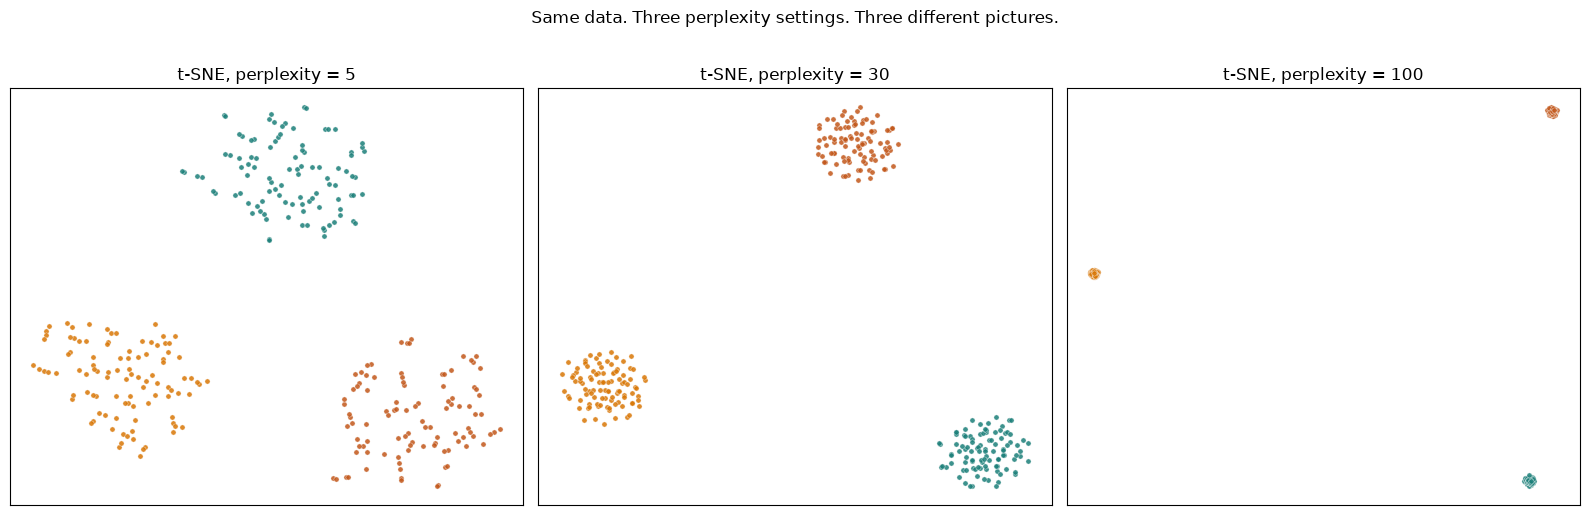

In [17]:
from sklearn.datasets import make_blobs
from sklearn.manifold import TSNE

# Simple dataset with three clusters in high-dimensional space
X_blobs, y_blobs = make_blobs(n_samples=300, centers=3,
                              n_features=20, random_state=0)

perplexities = [5, 30, 100]
embeddings = []
for p in perplexities:
    ts = TSNE(n_components=2, perplexity=p, random_state=0,
              init='pca', learning_rate='auto')
    embeddings.append(ts.fit_transform(X_blobs))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, emb, p in zip(axes, embeddings, perplexities):
    for cls, color in [(0, COLOR_A), (1, COLOR_B), (2, COLOR_PC2)]:
        mask = (y_blobs == cls)
        ax.scatter(emb[mask, 0], emb[mask, 1], c=color, s=14,
                   alpha=0.85, edgecolors='white', linewidths=0.3)
    ax.set_title(f't-SNE, perplexity = {p}')
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(alpha=0.2)

plt.suptitle('Same data. Three perplexity settings. Three different pictures.',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

The three panels do not agree on cluster sizes, cluster spacing, or even which clusters are near which. **None of them is "the truth".** Each is a local view that emphasizes different structure.

Use t-SNE to *look* at your data. Do not use it to *represent* your data for a downstream model. Its axes have no units, its distances are not preserved, and its output is stochastic. It cannot be evaluated without a task — and the task it was optimized for (local neighbourhood preservation in 2-D) is not the task your downstream model is trying to solve.

---

# Section 6 — Industrial example: sensor fusion on a wind turbine

A wind turbine has many correlated sensors. The operator wants a compact representation for downstream monitoring and anomaly detection. We will build a synthetic version with five hidden physical drivers:

- **Wind speed** (drives power, rotor speed)
- **Wind direction** (drives yaw, some vibration)
- **Thermal load** (drives temperatures)
- **Mechanical load** (drives vibration at several locations)
- **Ambient temperature** (drives thermal readings with a lag)

Fifteen observable channels mix these drivers with different weights and different noise levels.

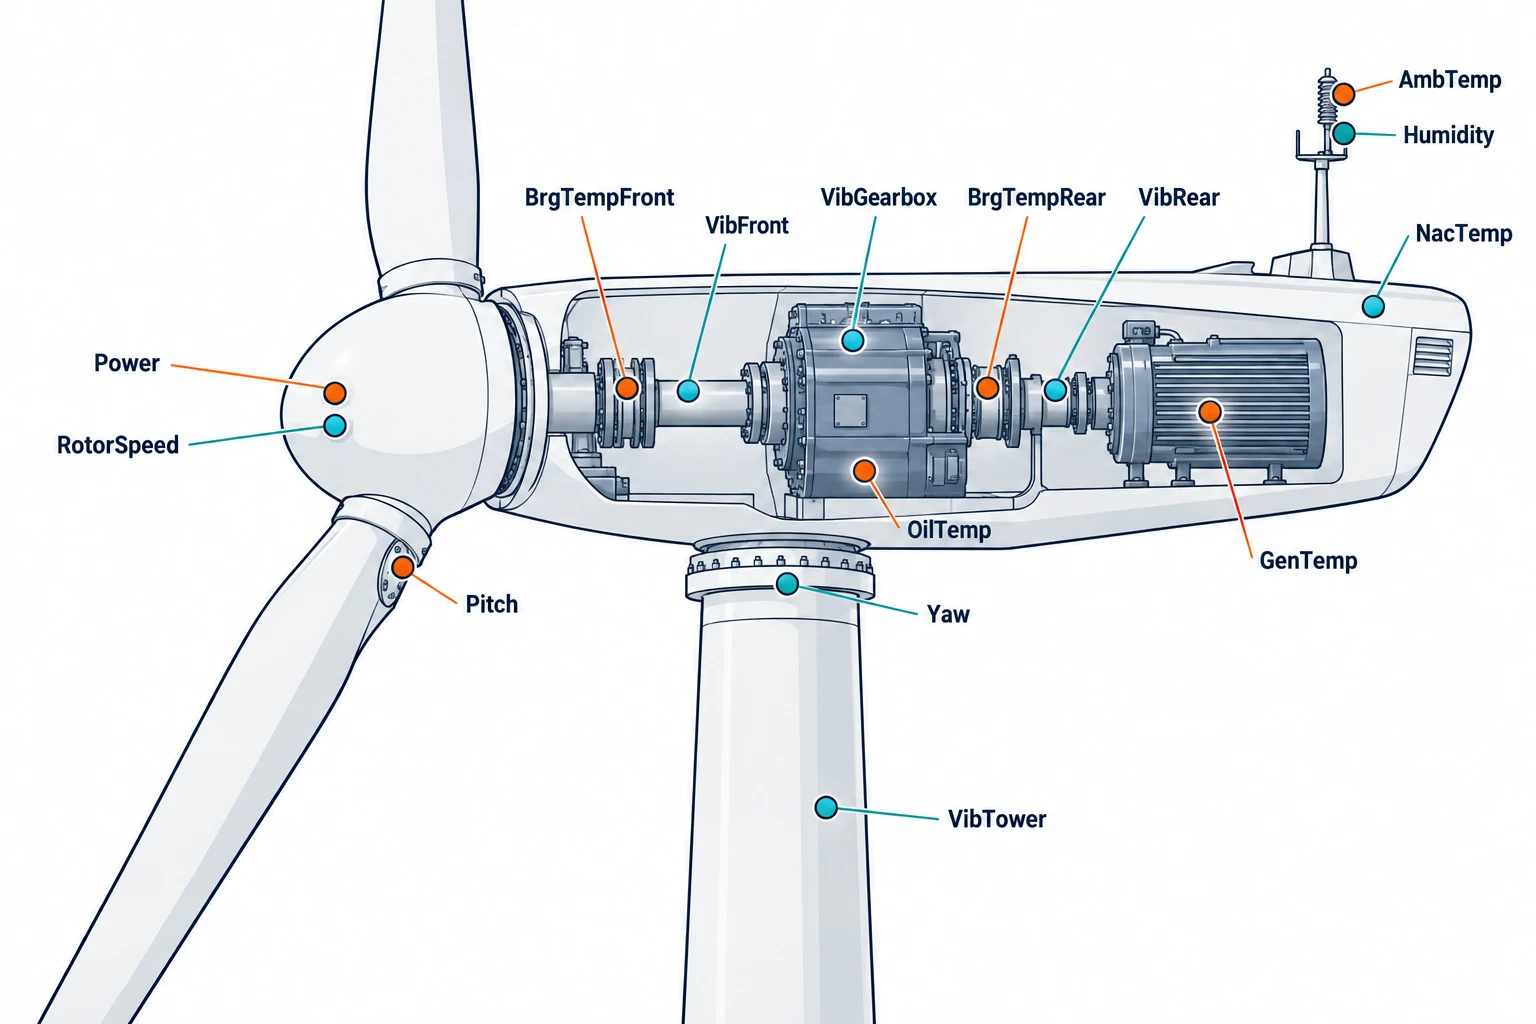

In [18]:
rng = np.random.default_rng(7)
n = 4000

# Hidden physical drivers
wind_speed   = rng.gamma(shape=2.0, scale=3.0, size=n)      # m/s
wind_dir     = rng.uniform(-np.pi, np.pi, n)                # radians
thermal_load = rng.normal(0, 1, n)
mech_load    = rng.gamma(shape=2.0, scale=1.5, size=n)
ambient      = 15 + 8 * np.sin(2 * np.pi * np.arange(n) / 500) + rng.normal(0, 1, n)

# Loading weights of each driver on each sensor
# Columns: wind_speed, wind_dir, thermal_load, mech_load, ambient
W = np.array([
    # power output
    [3.0,  0.2,  0.0,  0.3,  0.0],
    # rotor speed
    [2.0, -0.1,  0.0,  0.4,  0.0],
    # pitch angle
    [1.2,  0.3,  0.1,  0.0,  0.0],
    # yaw angle
    [0.1,  4.0,  0.0,  0.2,  0.0],
    # vibration: tower base
    [0.5,  0.2,  0.1,  2.5,  0.0],
    # vibration: nacelle front
    [0.3,  0.1,  0.0,  2.0,  0.0],
    # vibration: nacelle rear
    [0.2,  0.3,  0.1,  1.8,  0.0],
    # vibration: gearbox
    [0.4,  0.1,  0.2,  3.0,  0.1],
    # generator temperature
    [0.6,  0.0,  1.8,  0.9,  1.2],
    # gearbox oil temperature
    [0.4,  0.0,  2.0,  1.4,  0.8],
    # nacelle temperature
    [0.3,  0.0,  1.5,  0.3,  2.2],
    # bearing temperature (front)
    [0.5,  0.0,  1.2,  1.8,  0.4],
    # bearing temperature (rear)
    [0.4,  0.0,  1.0,  1.6,  0.5],
    # ambient sensor
    [0.0,  0.0,  0.1,  0.0,  3.5],
    # humidity sensor
    [0.1, -0.2,  0.4,  0.0,  1.5],
])

# Sensor names
sensor_names = [
    'Power', 'RotorSpeed', 'Pitch', 'Yaw',
    'VibTower', 'VibFront', 'VibRear', 'VibGearbox',
    'GenTemp', 'OilTemp', 'NacTemp',
    'BrgTempFront', 'BrgTempRear',
    'AmbTemp', 'Humidity',
]

# Combine drivers into a matrix, then apply the loading
S = np.c_[wind_speed, wind_dir, thermal_load, mech_load, ambient]
X_turbine = S @ W.T

# Add per-channel noise (some channels are noisier than others)
noise_levels = np.array([
    0.6, 0.5, 0.3, 0.4, 0.8, 0.9, 0.9, 1.0,
    0.7, 0.8, 0.6, 0.9, 0.9, 0.4, 0.5,
])
X_turbine += rng.normal(0, 1, X_turbine.shape) * noise_levels

print(f"Turbine data shape: {X_turbine.shape}")
print(f"Number of hidden drivers: 5")
print(f"Number of observed channels: 15")
print(X_turbine)

Turbine data shape: (4000, 15)
Number of hidden drivers: 5
Number of observed channels: 15
[[15.74356972 11.11306782  6.40847179 ... 12.33638038 57.18795869
  22.4032239 ]
 [13.32627921  8.15134515  5.04910701 ... 11.18902007 53.52518083
  23.75694773]
 [11.65116394  7.65258309  4.7351053  ...  9.82554901 50.68342665
  21.77120839]
 ...
 [12.04816232  8.23368263  5.24668983 ... 17.34228079 55.53973427
  24.00905949]
 [ 0.57004867  2.17784839 -0.17517526 ...  8.6033434  52.37059492
  21.63580281]
 [16.47255466 11.72224121  6.53912819 ... 12.09169494 51.30896046
  22.47218432]]


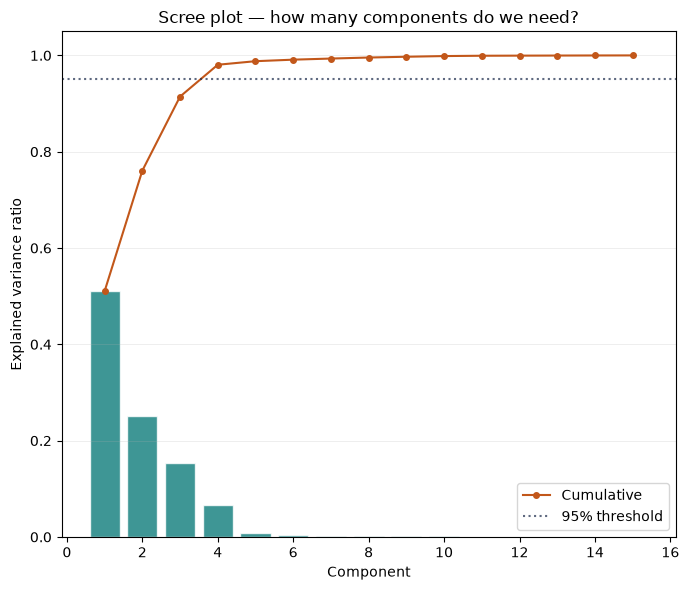

Components needed for 95% variance: 4
True number of drivers: 4


In [19]:
# Standardize each channel — otherwise channels with large units dominate
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_turbine)
X_std = scaler.transform(X_turbine)

# Run PCA
pca_turb = PCA(n_components=15).fit(X_std)

fig, ax = plt.subplots()
indices = np.arange(1, 16)
ax.bar(indices, pca_turb.explained_variance_ratio_,
       color=COLOR_PC1, alpha=0.8, edgecolor='white')
ax.plot(indices, np.cumsum(pca_turb.explained_variance_ratio_),
        color=COLOR_B, marker='o', markersize=4, linewidth=1.5,
        label='Cumulative')
ax.axhline(0.95, color=COLOR_LINE, linestyle=':', alpha=0.7,
           label='95% threshold')
ax.set_xlabel('Component')
ax.set_ylabel('Explained variance ratio')
ax.set_title('Scree plot — how many components do we need?')
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

cum = np.cumsum(pca_turb.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"Components needed for 95% variance: {k95}")
print(f"True number of drivers: 4")

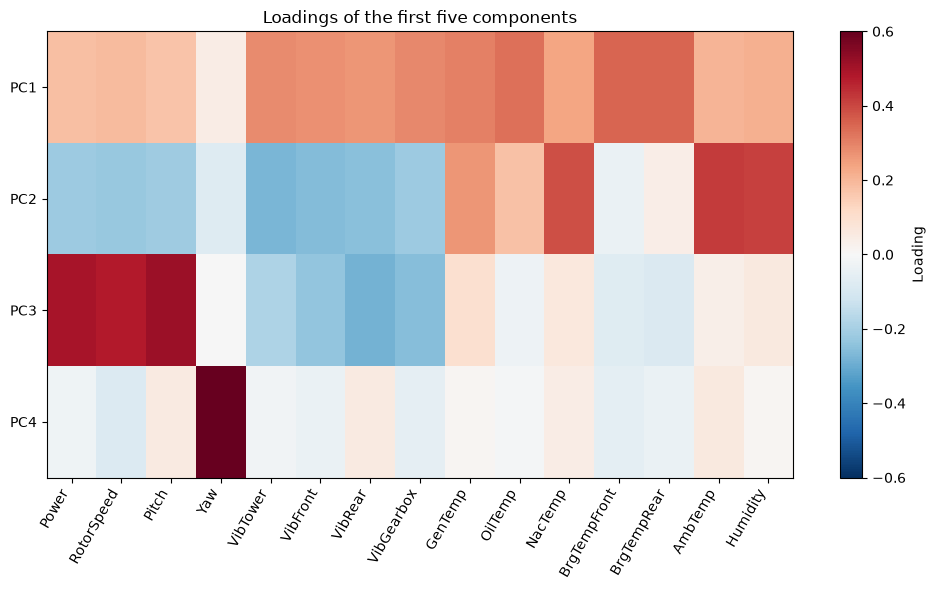

In [20]:
# Inspect the loadings of the first five components
loadings = pca_turb.components_[:4]

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(loadings, cmap='RdBu_r', aspect='auto',
               vmin=-0.6, vmax=0.6)

ax.set_xticks(np.arange(15))
ax.set_xticklabels(sensor_names, rotation=60, ha='right')
ax.set_yticks(np.arange(4))
ax.set_yticklabels([f'PC{i+1}' for i in range(4)])
ax.set_title('Loadings of the first five components')

plt.colorbar(im, ax=ax, label='Loading')
plt.tight_layout()
plt.show()

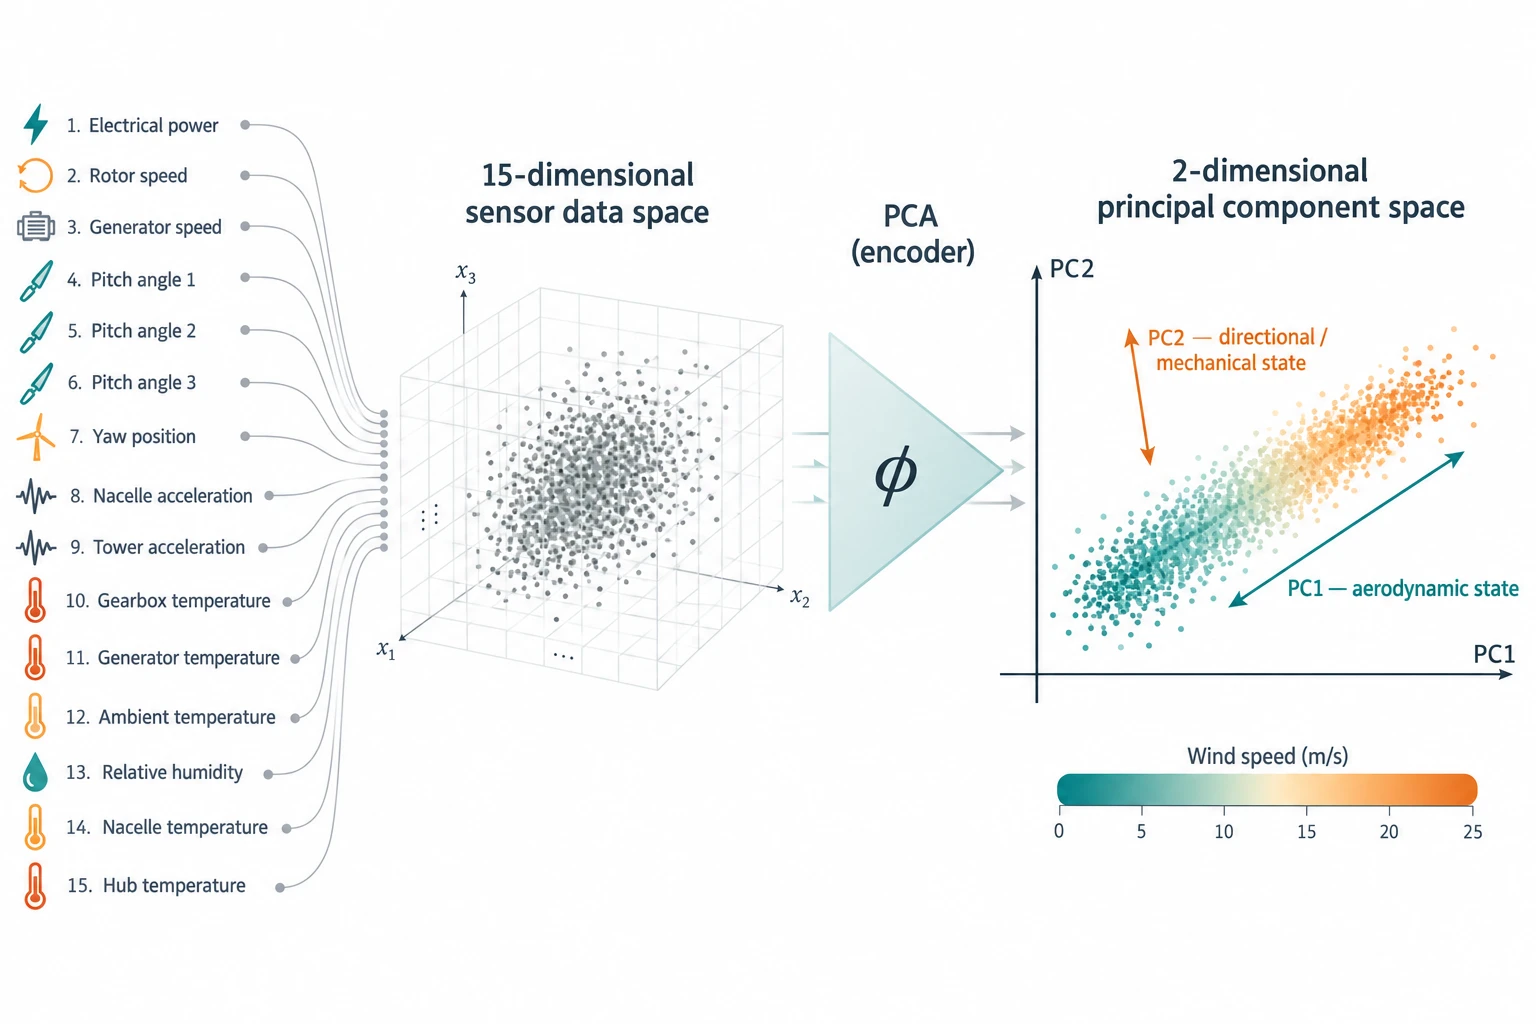

Look at the loading matrix. The first few components load heavily on recognizable groups of sensors:

- PC1 loads on power, rotor speed, and pitch — the **aerodynamic state**.
- PC2 loads on yaw and vibration — the **directional / mechanical state**.
- PC3 loads on temperatures — the **thermal state**.

This is what we hoped for. In this synthetic case, the physics cooperated with PCA. The hidden drivers happen to be aligned with the high-variance directions.

**In real wind turbines, this does not always work.** If a physical driver has small variance but matters for a task (say, an early fault signature), PCA will not find it. The loadings would be dominated by the drivers with the largest variance.

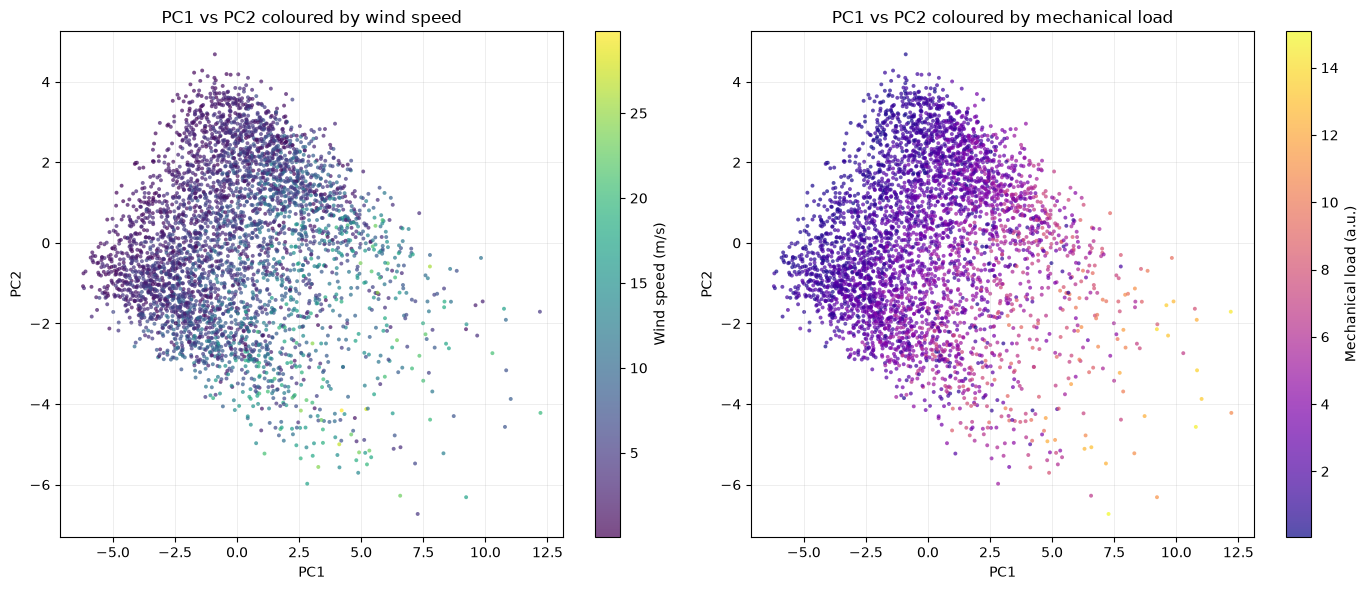

In [21]:
# Project to 2-D and colour by wind speed to see what PCA preserved
Z_turb = pca_turb.transform(X_std)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
sc = ax.scatter(Z_turb[:, 0], Z_turb[:, 1], c=wind_speed,
                cmap='viridis', s=8, alpha=0.7, edgecolors='none')
plt.colorbar(sc, ax=ax, label='Wind speed (m/s)')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('PC1 vs PC2 coloured by wind speed')
ax.grid(alpha=0.3)

ax = axes[1]
sc = ax.scatter(Z_turb[:, 0], Z_turb[:, 1], c=mech_load,
                cmap='plasma', s=8, alpha=0.7, edgecolors='none')
plt.colorbar(sc, ax=ax, label='Mechanical load (a.u.)')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('PC1 vs PC2 coloured by mechanical load')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The colour gradients tell us what each component captures. PC1 tracks wind speed (a strong linear gradient). PC2 is more subtle — it carries some directional and mechanical information.

This is exactly how engineers use PCA in practice: **to compress**, **to denoise**, **to inspect structure**. Not to replace physics. The components are a compact summary, not an explanation.

Digits: (1797, 64), classes: [0 1 2 3 4 5 6 7 8 9]


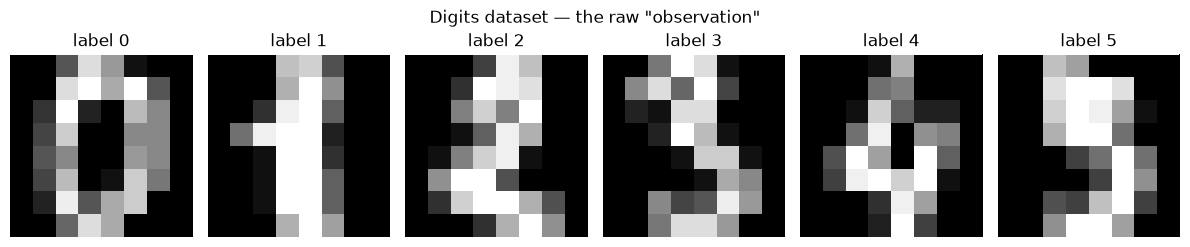

In [22]:
from sklearn.datasets import load_digits
digits = load_digits()
X_dig, y_dig = digits.data, digits.target
print(f"Digits: {X_dig.shape}, classes: {np.unique(y_dig)}")

# Digits are 8x8 grayscale images; each pixel is a feature.
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, i in zip(axes, range(6)):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(f"label {y_dig[i]}")
    ax.axis('off')
plt.suptitle('Digits dataset — the raw "observation"')
plt.tight_layout()
plt.show()

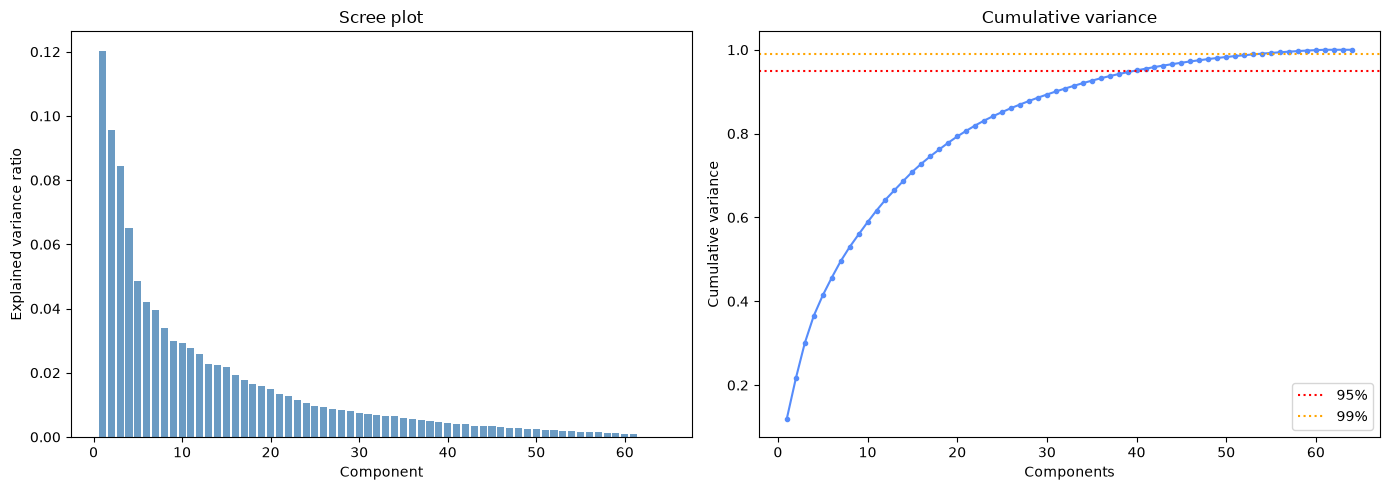

k for 95% variance: 40
k for 99% variance: 54


In [23]:
# Standardize (pixels are on the same scale, but useful to see effect)
X_dig_std = StandardScaler().fit_transform(X_dig)

# Full PCA
pca_dig = PCA().fit(X_dig_std)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(np.arange(1, 65), pca_dig.explained_variance_ratio_,
            color='steelblue', alpha=0.8)
axes[0].set(xlabel='Component', ylabel='Explained variance ratio',
            title='Scree plot')

cum = np.cumsum(pca_dig.explained_variance_ratio_)
axes[1].plot(np.arange(1, 65), cum, marker='o', markersize=3)
axes[1].axhline(0.95, color='red', ls=':', label='95%')
axes[1].axhline(0.99, color='orange', ls=':', label='99%')
axes[1].set(xlabel='Components', ylabel='Cumulative variance',
            title='Cumulative variance')
axes[1].legend()
plt.tight_layout()
plt.show()

k95 = np.searchsorted(cum, 0.95) + 1
k99 = np.searchsorted(cum, 0.99) + 1
print(f"k for 95% variance: {k95}")
print(f"k for 99% variance: {k99}")

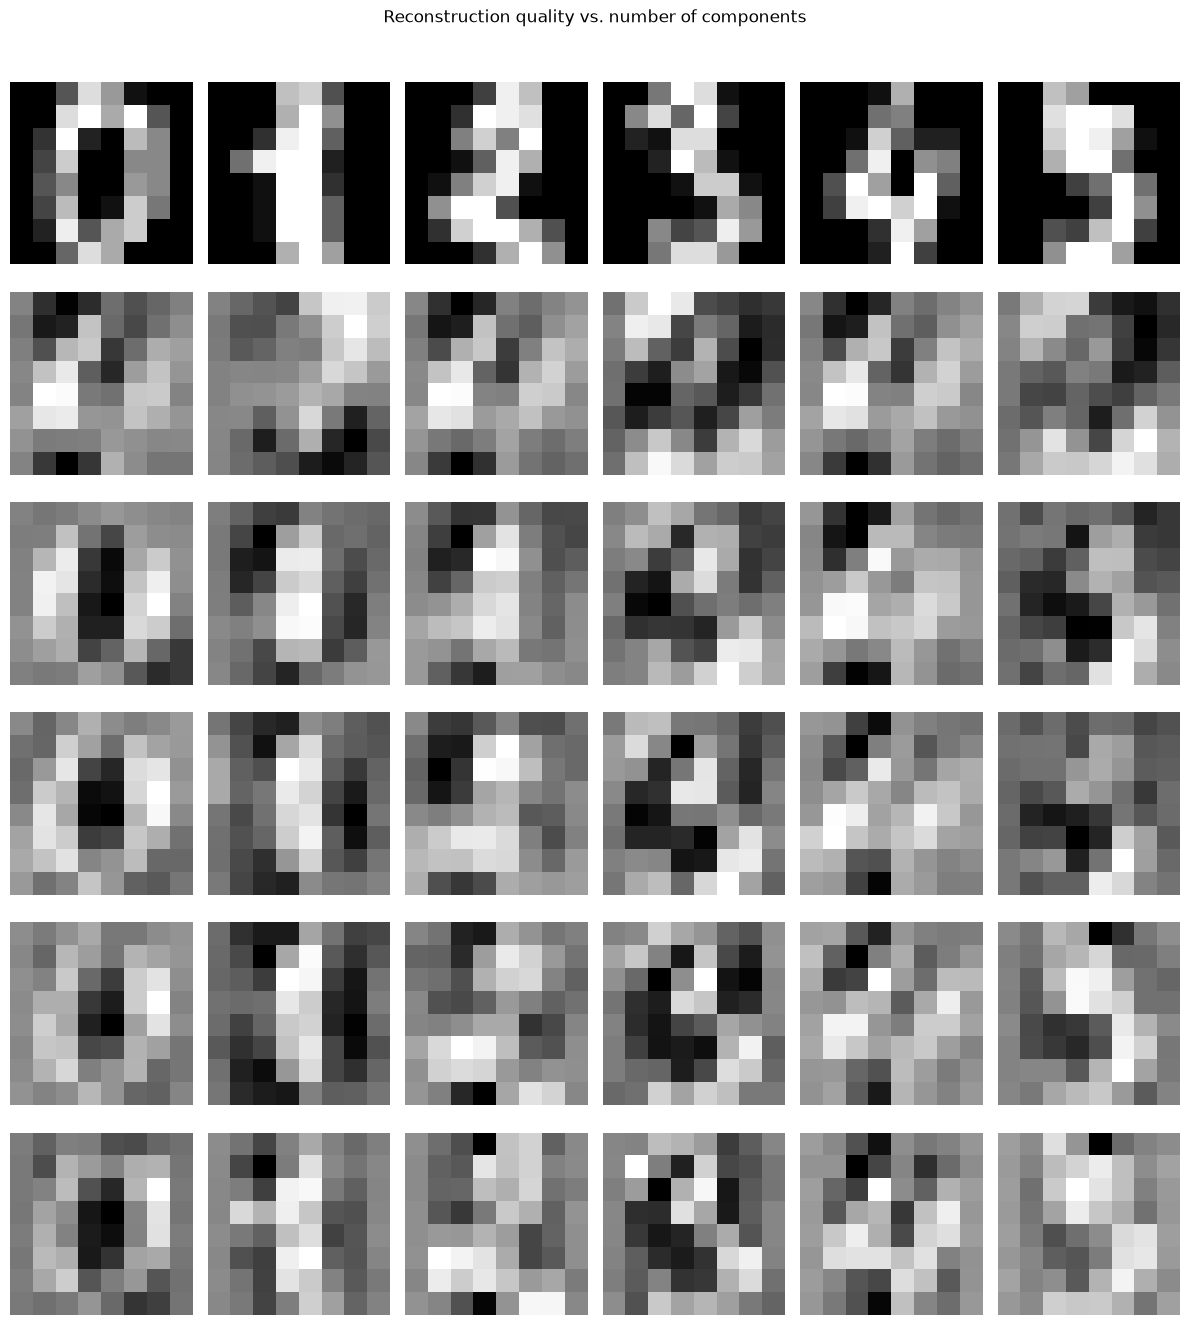

In [24]:
# Reconstruction: what does the digit look like at various k?
ks = [2, 5, 10, 20, 40]
fig, axes = plt.subplots(len(ks) + 1, 6, figsize=(12, 2.2 * (len(ks) + 1)))

# Original row
for ax, i in zip(axes[0], range(6)):
    ax.imshow(digits.images[i], cmap='gray')
    ax.axis('off')
axes[0, 0].set_ylabel('Original', fontsize=11)

for row, k in enumerate(ks, start=1):
    pca_k = PCA(n_components=k).fit(X_dig_std)
    X_rec = pca_k.inverse_transform(pca_k.transform(X_dig_std))
    for ax, i in zip(axes[row], range(6)):
        ax.imshow(X_rec[i].reshape(8, 8), cmap='gray')
        ax.axis('off')
    axes[row, 0].set_ylabel(f'k={k}', fontsize=11)

plt.suptitle('Reconstruction quality vs. number of components', y=1.01)
plt.tight_layout()
plt.show()

---

# Section 7 — Summary

Session 0 was about the wrong **shape**. Session 1 was about the wrong **coordinates**. Session 2 asked: can we find the coordinates without the physics?

The answer is **a qualified yes**:

1. **PCA finds directions of maximum variance.** It is a real tool, and it works when the phenomenon's important directions happen to carry most of the variance.
2. **PCA is not a physics engine.** When the useful structure is a small-variance direction, PCA buries it. The variance sweep on the cantilever showed exactly this.
3. **Uncorrelated is not independent.** PCA misses structure that has zero linear correlation — the circle example.
4. **PCA is a latent variable model.** The latent vector is the representation; the eigendecomposition is the algorithm. This framing generalizes to clustering, density estimation, and autoencoders.
5. **Visualization is not validation.** t-SNE and UMAP are for looking, not for representing. Their outputs are not features.
6. **The industrial case works when physics cooperates.** In the synthetic wind turbine, the hidden drivers align with high-variance directions and the loadings are interpretable. In real systems this alignment is not guaranteed, and the interpretation step is where prior knowledge re-enters.

**The question we leave with:** If we need physics to know which direction matters, and physics does not always align with variance, when can we trust a data-driven representation?